# Examen Módulo 2 — Evaluación de métodos de regresión

## Estabilidad de redes eléctricas (`stab`)

**Alumno:** Christian Isaac Dzul Canul  
**Matrícula:** A17003832 

**Objetivo.** Aplicar y comparar distintos métodos de regresión sobre un problema real de estabilidad de redes 
eléctricas. Al finalizar la práctica, el estudiante deberá ser capaz de implementar, entrenar y evaluar 
correctamente modelos de regresión lineal, regresión polinomial (con y sin regularización), máquinas de 
soporte vectorial para regresión (SVR) y árboles de decisión, utilizando validación cruzada y un conjunto 
de prueba independiente, para después comparar su desempeño de forma crítica y fundamentada

**Metodología.**
1. **Validación cruzada de 5 particiones** sobre `electrical_grid_stability_train.csv` (8,000 filas): selección de hiperparámetros y estimación del desempeño (media ± desviación de RMSE, MAE y $R^2$).
2. **Evaluación final**: cada modelo elegido se reentrena con las 8,000 filas y genera predicciones para `electrical_grid_stability_test.csv` (2,000 filas). Si el archivo trae la columna `stab`, se calcula e imprime el RMSE de cada modelo.

| Sección | Contenido |
|---|---|
| 0 | Librerías y versiones |
| 1 | Análisis exploratorio de datos (EDA) |
| 2 | Preprocesamiento |
| 3 | Modelos: lineal, polinomial, polinomial + Ridge, SVR, árbol |
| 4 | Tabla comparativa |
| 5 | Evaluación en el conjunto de prueba |
| 6 | Conclusiones |

## 0. Librerías y versiones

Librerías utilizadas: **Python**, **NumPy**, **pandas**, **Matplotlib** y **scikit-learn** (con **SciPy** como dependencia de scikit-learn). La celda siguiente imprime las versiones exactas del entorno donde se ejecuta el notebook.

In [1]:
import sys, time, warnings
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn

from sklearn.model_selection import KFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

versiones = pd.DataFrame({"versión": {
    "Python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__}})
versiones

,versión
Python,3.13.16
numpy,2.4.4
pandas,3.0.2
matplotlib,3.10.8
scipy,1.17.1
scikit-learn,1.8.0


## 1. Análisis exploratorio de datos (EDA)

#### **A)** Carga y calidad de los datos

In [2]:
# Carga de datos de entrenamiento
RUTA_TRAIN = Path("electrical_grid_stability_train.csv") 
train = pd.read_csv(RUTA_TRAIN)

# Definición de variables para el análisis 
TAU = ["tau1", "tau2", "tau3", "tau4"]
POT = ["p1", "p2", "p3", "p4"]
ELA = ["g1", "g2", "g3", "g4"]
OBJETIVO = "stab"


print("Dimensiones:", train.shape)
print("Tipos:", train.dtypes.value_counts().to_dict())
print("Valores faltantes:", int(train.isna().sum().sum()))
print("Filas duplicadas:", int(train.duplicated().sum()))
train.head()

Dimensiones: (8000, 13)
Tipos: {dtype('float64'): 13}
Valores faltantes: 0
Filas duplicadas: 0


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


In [3]:
resumen = train.describe().T
resumen["asimetría"] = train.skew()
resumen["curtosis_exc"] = train.kurt()
resumen.round(3)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis_exc
tau1,8000.0,5.236,2.736,0.501,2.867,5.226,7.598,9.999,0.001,-1.198
tau2,8000.0,5.242,2.753,0.500,2.844,5.251,7.632,10.000,0.000,-1.207
tau3,8000.0,5.253,2.742,0.501,2.885,5.249,7.627,9.999,0.000,-1.200
tau4,8000.0,5.244,2.756,0.502,2.855,5.246,7.619,9.999,-0.002,-1.204
p1,8000.0,3.751,0.756,1.583,3.216,3.748,4.288,5.827,-0.005,-0.394
p2,8000.0,-1.250,0.431,-2.000,-1.624,-1.247,-0.879,-0.500,-0.007,-1.191
p3,8000.0,-1.251,0.433,-2.000,-1.624,-1.253,-0.876,-0.500,0.003,-1.197
p4,8000.0,-1.250,0.433,-2.000,-1.626,-1.248,-0.877,-0.500,-0.002,-1.197
g1,8000.0,0.522,0.274,0.050,0.283,0.520,0.758,1.000,0.012,-1.199
g2,8000.0,0.523,0.275,0.050,0.284,0.522,0.761,1.000,0.014,-1.204


In [4]:
# Balance de potencia de la red: p1 = -(p2 + p3 + p4)
balance = train[POT].sum(axis=1)
print(f"max |p1 + p2 + p3 + p4| = {balance.abs().max():.2e}")
print(f"Correlación p1 vs -(p2+p3+p4): {np.corrcoef(train['p1'], -(train[['p2', 'p3', 'p4']].sum(axis=1)))[0, 1]:.6f}")

# Variable objetivo: proporción de sistemas inestables (stab > 0)
print(f"\nstab > 0 (inestable): {100 * (train[OBJETIVO] > 0).mean():.1f} %   |   stab <= 0 (estable): {100 * (train[OBJETIVO] <= 0).mean():.1f} %")

max |p1 + p2 + p3 + p4| = 1.00e-09
Correlación p1 vs -(p2+p3+p4): 1.000000

stab > 0 (inestable): 63.6 %   |   stab <= 0 (estable): 36.4 %


#### **B)** Distribución de cada variable

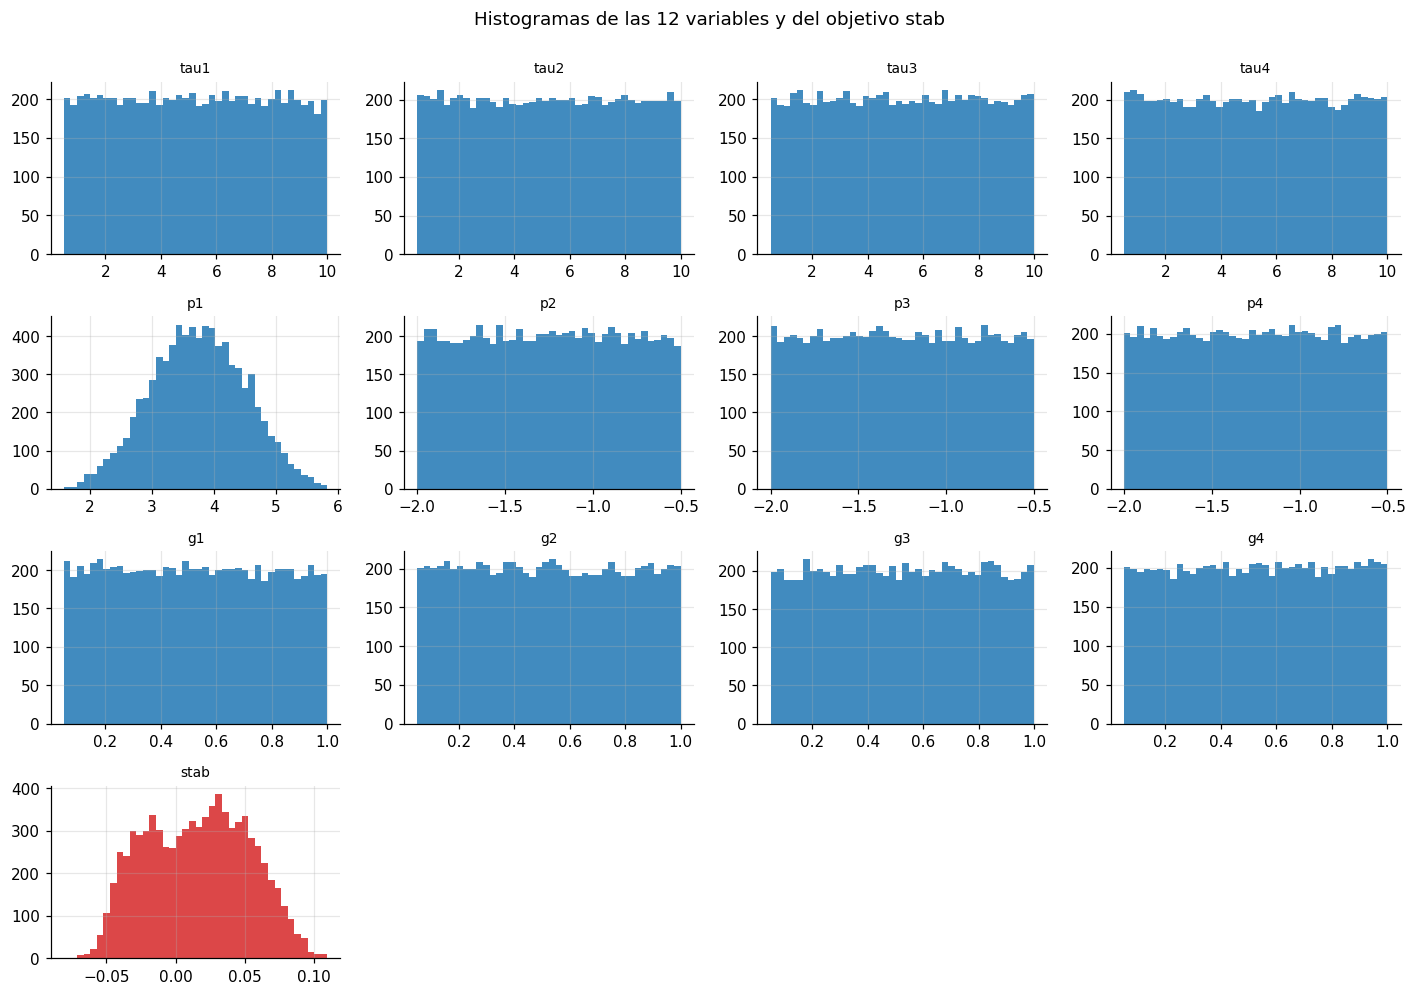

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(13, 9))
for ax, col in zip(axes.ravel(), train.columns):
    ax.hist(train[col], bins=40, color="C3" if col == OBJETIVO else "C0", alpha=0.85)
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(train.columns):]:
    ax.axis("off")
plt.suptitle("Histogramas de las 12 variables y del objetivo stab", y=1.0)
plt.tight_layout(); plt.show()

#### **C)** Valores atípicos (regla del IQR)

                  tau1  tau2  tau3  tau4    p1   p2   p3   p4   g1   g2   g3   g4  stab
atípicos (k=1.5)   0.0   0.0   0.0   0.0  1.00  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0
atípicos (k=3)     0.0   0.0   0.0   0.0  0.00  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0
% (k=1.5)          0.0   0.0   0.0   0.0  0.01  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0


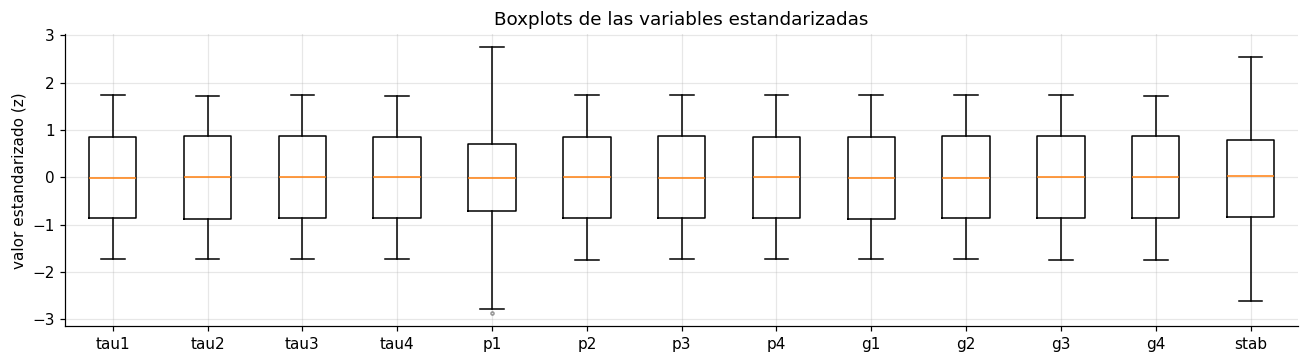

In [6]:
def atipicos_iqr(s, k):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - k * iqr) | (s > q3 + k * iqr)).sum())

tabla_atip = pd.DataFrame({"atípicos (k=1.5)": {c: atipicos_iqr(train[c], 1.5) for c in train.columns},
                           "atípicos (k=3)":   {c: atipicos_iqr(train[c], 3.0) for c in train.columns}})
tabla_atip["% (k=1.5)"] = (100 * tabla_atip["atípicos (k=1.5)"] / len(train)).round(2)
print(tabla_atip.T.to_string())

z = (train - train.mean()) / train.std()
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.boxplot([z[c] for c in train.columns], flierprops=dict(marker="o", ms=2, alpha=0.4))
ax.set_xticks(range(1, len(train.columns) + 1)); ax.set_xticklabels(train.columns)
ax.set_ylabel("valor estandarizado (z)"); ax.set_title("Boxplots de las variables estandarizadas")
plt.tight_layout(); plt.show()

#### **D)** Correlaciones entre predictores y con `stab`

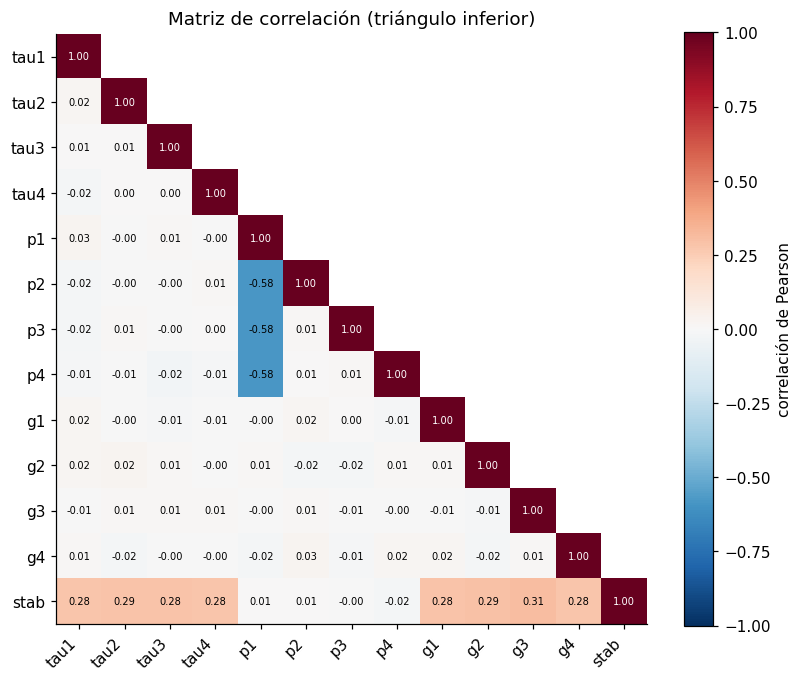

      Pearson  Spearman
p4     -0.016    -0.016
p3     -0.003    -0.000
p2      0.005     0.005
p1      0.008     0.006
tau1    0.277     0.277
g4      0.278     0.274
tau4    0.280     0.279
tau3    0.282     0.283
g1      0.283     0.280
tau2    0.286     0.286
g2      0.292     0.287
g3      0.309     0.307

Pares de predictores con |r| > 0.1:
p1  p3    0.585
    p4    0.585
    p2    0.579


In [7]:
corr = train.corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.ma.masked_where(mask, corr.values), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="correlación de Pearson"); ax.grid(False)
ax.set_title("Matriz de correlación (triángulo inferior)")
plt.tight_layout(); plt.show()

corr_obj = pd.DataFrame({"Pearson": train.corr()[OBJETIVO], "Spearman": train.corr(method="spearman")[OBJETIVO]}).drop(OBJETIVO)
print(corr_obj.round(3).sort_values("Pearson").to_string())

predictores_todos = TAU + POT + ELA
cp = train[predictores_todos].corr().where(~np.eye(12, dtype=bool)).abs()
pares = cp.where(np.triu(np.ones(cp.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("\nPares de predictores con |r| > 0.1:")
print(pares[pares > 0.1].round(3).to_string())

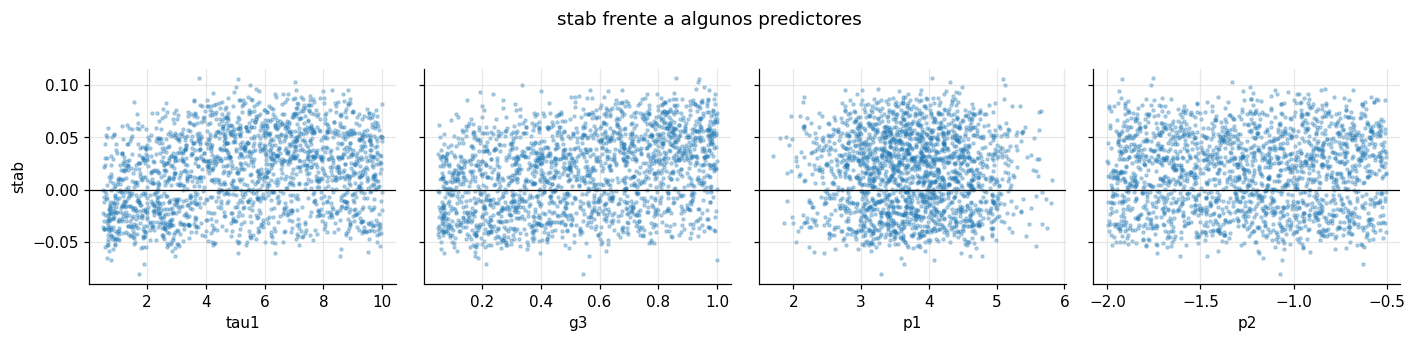

In [8]:
# Relación de stab con algunos predictores (muestra de 2,000 filas/registros)
muestra_eda = train.sample(2000, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0), sharey=True)
for ax, col in zip(axes, ["tau1", "g3", "p1", "p2"]):
    ax.scatter(muestra_eda[col], muestra_eda[OBJETIVO], s=4, alpha=0.3)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(col)
axes[0].set_ylabel("stab")
plt.suptitle("stab frente a algunos predictores", y=1.02); plt.tight_layout(); plt.show()

#### **E)** Hallazgos del EDA

- **Calidad:** El csv contiene 8,000 filas y 13 columnas numérica, sin valores faltantes ni duplicados.

- **Distribuciones:** Se puede observar a `tau1–tau4` (0.5 a 10), `p2–p4` (−2 a −0.5) y `g1–g4` (0.05 a 1) son prácticamente uniformes dentro de su rango, ademas, la asimetría aprox 0 con muy ligeros cambios pero siempre cerca de 0, y la curtosis en su mayoria entre −1.2 (la de una uniforme). En las graficas, la distribucion en `p1` tiene forma de campana (1.58 a 5.83) porque es la suma de tres uniformes.

- **Atípicos:** La regla del IQR marca 1 en un solo valor (en `p1`, con k = 1.5) y ninguno con k = 3. Todos los valores están dentro de rangos físicos acotados, así que dado estos hallazgos no tendra un gran impacto al no ser muchos valos, por lo que vi conveniente mantenerlo y no aplicar ningún tratamiento de atípicos.

- **Redundancia:** Se confirma el balance de potencia $p_1 = -(p_2+p_3+p_4)$ (error máximo de $10^{-9}$, correlación 1.000). Por eso `p1` se correlaciona con un valor aproximado de 0.58 con `p2`, `p3` y `p4`, en cuanto al resto de los predictores, son prácticamente independientes entre si.

- **Objetivo `stab`:** Se puede observar con una media de 0.016, desviación de 0.037, un rango entre −0.081 a 0.109, distribución casi simétrica. Ademas, el **63.6 %** de los casos son inestables.

- **Relación con `stab`:** Los tiempos de reacción `tau` y las elasticidades `g` tienen correlaciones positivas y moderadas (0.28 a 0.31): reacciones más lentas y mayor elasticidad al precio se asocian con más inestabilidad. Las potencias `p` tienen correlación aproximada de 0. Pearson y Spearman coinciden, pero las nubes de puntos son muy anchas, ninguna variable explica `stab` por sí sola. La estabilidad depende de combinaciones no lineales de varias variables, lo que anticipa que un modelo lineal se quedará corto y que los modelos flexibles (polinomios, kernels) tendrán ventaja.

## 2. Preprocesamiento

**Decisiones:**

1. **Separar predictores y objetivo.** Predictores: `tau1–tau4`, `p1–p4`, `g1–g4`y objetivo: `stab`.

2. **Eliminar `p1` de los predictores.** El EDA confirma que $p_1 = -(p_2+p_3+p_4)$ exactamente (error máximo aprox en $10^{-9}$). `p1` no aporta información nueva y crea **colinealidad perfecta**. En la regresión lineal y polinomial eso vuelve singular a $X^\top X$ (coeficientes no únicos) y en el polinomio multiplica columnas redundantes. Quitarla no pierde información: cualquier modelo puede reconstruirla de `p2–p4`. Para que la comparación sea justa, se usan los **mismos 11 predictores** en los cinco modelos.

3. **Sin imputación ni tratamiento de atípicos.** No hay faltantes, duplicados ni valores fuera de rango: las variables son simuladas y casi uniformes dentro de rangos físicos acotados.

4. **Escalado con `StandardScaler`** dentro de un `Pipeline` para los modelos que lo requieren: polinomial (las potencias de variables con escalas distintas se descompensan), Ridge (la penalización trata igual a todos los coeficientes) y SVR (el kernel RBF usa distancias). En la regresión lineal no cambia las predicciones, pero se incluye para comparar los coeficientes. El árbol no se escala, solo compara cada variable con un umbral.

5. **Todo dentro de `Pipeline`**: El escalador se ajusta solo con los datos de entrenamiento de cada partición, sin fuga de datos.

6. **Protocolo de validación común:** `KFold(5, shuffle=True, random_state=42)`, las mismas 5 particiones para todos los modelos y todas las búsquedas de hiperparámetros. Métrica principal: RMSE (en las unidades de `stab`), también utilice MAE y $R^2$.

In [9]:
PREDICTORES = TAU + ["p2", "p3", "p4"] + ELA          # 11 predictores (sin p1, redundante)
X = train[PREDICTORES]
y = train[OBJETIVO]
print("X:", X.shape, "  y:", y.shape)

RANDOM_STATE = 42
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
METRICAS = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

resultados = {}      # métricas de validación cruzada del mejor modelo de cada familia
finales = {}         # mejor modelo de cada familia, reentrenado con las 8,000 filas


def evalua_cv(modelo, Xd=X):
    # Validación cruzada de 5 particiones: media y desviación de RMSE, MAE y R2 (validación) y RMSE de entrenamiento
    r = cross_validate(modelo, Xd, y, cv=kf, scoring=METRICAS, return_train_score=True, n_jobs=-1)
    return {"RMSE": -r["test_RMSE"].mean(), "RMSE_std": r["test_RMSE"].std(),
            "MAE": -r["test_MAE"].mean(), "MAE_std": r["test_MAE"].std(),
            "R2": r["test_R2"].mean(), "R2_std": r["test_R2"].std(),
            "RMSE_entren": -r["train_RMSE"].mean(),
            "RMSE_por_fold": np.round(-r["test_RMSE"], 5)}


def desde_busqueda(busq):
    # Métricas de validación cruzada del mejor candidato de un GridSearchCV multi-métrica (mismas 5 particiones)
    r, i = busq.cv_results_, busq.best_index_
    return {"RMSE": -r["mean_test_RMSE"][i], "RMSE_std": r["std_test_RMSE"][i],
            "MAE": -r["mean_test_MAE"][i], "MAE_std": r["std_test_MAE"][i],
            "R2": r["mean_test_R2"][i], "R2_std": r["std_test_R2"][i],
            "RMSE_entren": -r["mean_train_RMSE"][i],
            "RMSE_por_fold": np.round([-r[f"split{k}_test_RMSE"][i] for k in range(5)], 5)}


def muestra(res):
    return (f"RMSE = {res['RMSE']:.5f} ± {res['RMSE_std']:.5f} | MAE = {res['MAE']:.5f} ± {res['MAE_std']:.5f} | "
            f"R² = {res['R2']:.4f} ± {res['R2_std']:.4f} | RMSE entren. = {res['RMSE_entren']:.5f}")


# Línea base de referencia: predecir siempre la media de stab
base = evalua_cv(DummyRegressor(strategy="mean"))
print("Línea base (promedio):", muestra(base))

X: (8000, 11)   y: (8000,)
Línea base (promedio): RMSE = 0.03694 ± 0.00044 | MAE = 0.03135 ± 0.00048 | R² = -0.0001 ± 0.0001 | RMSE entren. = 0.03695


## 3. Implementación y entrenamiento de modelos

#### **A)** Regresión lineal
Modelo $\hat y = b + \sum_j w_j x_j$ | No tiene hiperparámetros.

RMSE = 0.02209 ± 0.00047 | MAE = 0.01754 ± 0.00045 | R² = 0.6422 ± 0.0176 | RMSE entren. = 0.02205    (0.6 s)


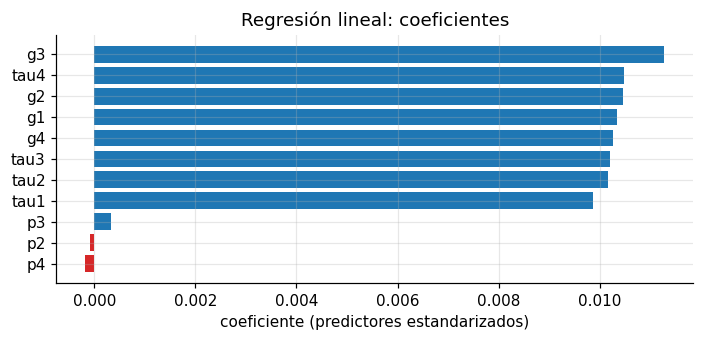

In [10]:
t0 = time.time()
lineal = Pipeline([("scaler", StandardScaler()), ("modelo", LinearRegression())])
resultados["Regresión lineal"] = evalua_cv(lineal)
finales["Regresión lineal"] = lineal.fit(X, y)
print(muestra(resultados["Regresión lineal"]), f"   ({time.time() - t0:.1f} s)")

coef = pd.Series(lineal.named_steps["modelo"].coef_, index=PREDICTORES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(coef.index, coef.values, color=["C3" if v < 0 else "C0" for v in coef.values])
ax.set_xlabel("coeficiente (predictores estandarizados)"); ax.set_title("Regresión lineal: coeficientes")
plt.tight_layout(); plt.show()

**Interpretación:**

 La regresión lineal explica el **64 %** de la variación de `stab` ($R^2$ = 0.642) y baja el RMSE de 0.0369 (línea base) a **0.0221**, un 40 % menos. Los errores de entrenamiento (0.02205) y de validación (0.02209) son prácticamente iguales, no hay sobreajuste, pero sí sesgo alto (subajuste). El modelo es demasiado rígido para una relación no lineal. Los coeficientes coinciden con el EDA, siendo que `tau` y `g` positivos y de magnitud parecida, mientras que `p2–p4` casi en cero.

#### **B)** Regresión polinomial sin regularización
`StandardScaler → PolynomialFeatures(grado) → LinearRegression`. 

Se exploran los grados **2, 3 y 4**

       columnas  RMSE_entren  RMSE_CV  RMSE_std    R2_CV  seg  brecha_%
grado                                                                  
2            77      0.01215  0.01234   0.00012  0.88841  0.6   1.50629
3           363      0.00808  0.00872   0.00017  0.94423  0.7   7.98286
4          1364      0.00590  0.00812   0.00015  0.95169  3.1  37.70691


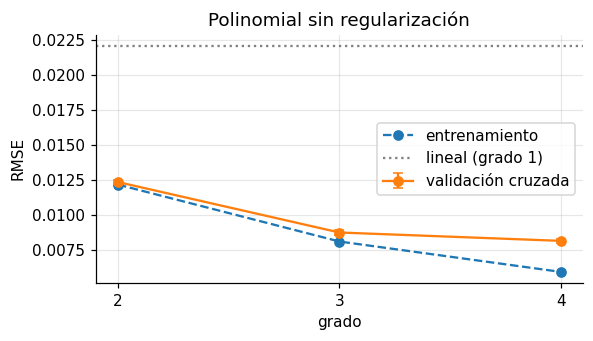

In [11]:
filas, por_grado = [], {}
for grado in [2, 3, 4]:
    t0 = time.time()
    modelo = Pipeline([("scaler", StandardScaler()),
                       ("poli", PolynomialFeatures(degree=grado, include_bias=False)),
                       ("modelo", LinearRegression())])
    res = evalua_cv(modelo)
    por_grado[grado] = (modelo, res)
    filas.append({"grado": grado, "columnas": comb(11 + grado, grado) - 1, "RMSE_entren": res["RMSE_entren"],
                  "RMSE_CV": res["RMSE"], "RMSE_std": res["RMSE_std"], "R2_CV": res["R2"], "seg": round(time.time() - t0, 1)})
tabla_poli = pd.DataFrame(filas).set_index("grado")
tabla_poli["brecha_%"] = 100 * (tabla_poli["RMSE_CV"] / tabla_poli["RMSE_entren"] - 1)
print(tabla_poli.round(5).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(tabla_poli.index, tabla_poli["RMSE_entren"], "o--", label="entrenamiento")
ax.errorbar(tabla_poli.index, tabla_poli["RMSE_CV"], yerr=tabla_poli["RMSE_std"], fmt="o-", capsize=3, label="validación cruzada")
ax.axhline(resultados["Regresión lineal"]["RMSE"], color="gray", ls=":", label="lineal (grado 1)")
ax.set_xticks([2, 3, 4]); ax.set_xlabel("grado"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("Polinomial sin regularización")
plt.tight_layout(); plt.show()

In [12]:
GRADO_POLI = 4     # grado elegido con validación cruzada (ver justificación abajo)
modelo_poli, res_poli = por_grado[GRADO_POLI]
resultados[f"Polinomial grado {GRADO_POLI} (sin reg.)"] = res_poli
finales[f"Polinomial grado {GRADO_POLI} (sin reg.)"] = modelo_poli.fit(X, y)
print(muestra(res_poli))

RMSE = 0.00812 ± 0.00015 | MAE = 0.00564 ± 0.00015 | R² = 0.9517 ± 0.0008 | RMSE entren. = 0.00590


**Interpretación y elección del grado:**
- **Grado 2:** RMSE CV 0.01234 ($R^2$ = 0.888), con una brecha de solo 1.5 % entre entrenamiento y validación. Captar curvaturas e interacciones de segundo orden ya reduce el error lineal a casi la mitad.
- **Grado 3:** 0.00872 ($R^2$ = 0.944); la brecha sube a 8 %.
- **Grado 4:** 0.00812 ($R^2$ = 0.952), el mejor en validación. Pero el error de entrenamiento cae a 0.00590 y la brecha llega a 38 %, la varianza empieza a crecer (1,364 columnas y aprox 10 veces más tiempo de cómputo).

Por ello, decidi escoger el **grado 4** porque minimiza el RMSE de validación. La mejora sobre el grado 3 (0.0006) es unas cuatro veces la desviación entre folds (aprox 0.00015), y el grado 4 gana en las 5 particiones es una mejora real. La brecha creciente indica que subir a grado 5 probablemente empeoraría la validación. Si se priorizara un modelo más simple y barato, el grado 3 sería una alternativa razonable.

#### **C)** Regresión polinomial con regularización (Ridge)
`StandardScaler → PolynomialFeatures → Ridge`. 

Se busca **conjuntamente** el grado y la fuerza de regularización $\alpha$ con `GridSearchCV` (las mismas 5 particiones). Escogi **Ridge** porque reparte el peso entre las muchas columnas polinomiales correlacionadas entre sí y tiene solución cerrada.

Mejores hiperparámetros: {'poli__degree': 4, 'ridge__alpha': np.float64(1.0)}   RMSE CV = 0.00812   (4.6 s)

RMSE de validación cruzada (filas: alpha, columnas: grado):
param_poli__degree        2        3        4
0.001               0.01234  0.00872  0.00812
0.01                0.01234  0.00872  0.00812
0.1                 0.01234  0.00872  0.00812
1                   0.01234  0.00872  0.00812
10                  0.01234  0.00872  0.00814
100                 0.01234  0.00903  0.00905
1000                0.01325  0.01174  0.01251


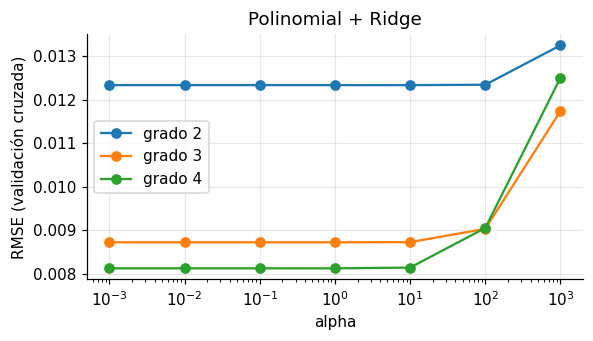

In [13]:
t0 = time.time()
pipe_ridge = Pipeline([("scaler", StandardScaler()),
                       ("poli", PolynomialFeatures(include_bias=False)),
                       ("ridge", Ridge())])
malla_ridge = {"poli__degree": [2, 3, 4], "ridge__alpha": np.logspace(-3, 3, 7)}
busq_ridge = GridSearchCV(pipe_ridge, malla_ridge, cv=kf, scoring=METRICAS, refit="RMSE",
                          return_train_score=True, n_jobs=-1)
busq_ridge.fit(X, y)
print(f"Mejores hiperparámetros: {busq_ridge.best_params_}   RMSE CV = {-busq_ridge.best_score_:.5f}   ({time.time() - t0:.1f} s)")

tabla_ridge = (pd.DataFrame(busq_ridge.cv_results_)
               .assign(RMSE=lambda d: -d["mean_test_RMSE"])
               .pivot(index="param_ridge__alpha", columns="param_poli__degree", values="RMSE"))
alphas = tabla_ridge.index.astype(float)
tabla_ridge.index = [f"{a:g}" for a in alphas]
print("\nRMSE de validación cruzada (filas: alpha, columnas: grado):")
print(tabla_ridge.round(5).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for g in tabla_ridge.columns:
    ax.semilogx(alphas, tabla_ridge[g].values, "o-", label=f"grado {g}")
ax.set_xlabel("alpha"); ax.set_ylabel("RMSE (validación cruzada)"); ax.legend(); ax.set_title("Polinomial + Ridge")
plt.tight_layout(); plt.show()

In [14]:
nombre_ridge = f"Polinomial grado {busq_ridge.best_params_['poli__degree']} + Ridge (α={busq_ridge.best_params_['ridge__alpha']:g})"
resultados[nombre_ridge] = desde_busqueda(busq_ridge)
finales[nombre_ridge] = busq_ridge.best_estimator_          # GridSearchCV ya lo reentrenó con las 8,000 filas
print(nombre_ridge); print(muestra(resultados[nombre_ridge]))

Polinomial grado 4 + Ridge (α=1)
RMSE = 0.00812 ± 0.00015 | MAE = 0.00563 ± 0.00015 | R² = 0.9517 ± 0.0008 | RMSE entren. = 0.00590


**Interpretación:** 

La búsqueda conjunta eligió **grado 4 con α = 1**, con RMSE CV **0.00812**, idéntico (a 5 decimales) al polinomio sin regularizar.

- Con α ≤ 10 el error no cambia. Con α = 100 empeora (0.00905) y con α = 1000 mucho más (0.01251): demasiada penalización produce sesgo.
- La regularización **casi no aporta aquí** porque el problema no está en alta dimensión: cada fold entrena con 6,400 filas para 1,364 columnas (≈ 4.7 filas por coeficiente) y el sobreajuste del grado 4 es moderado. Coincide con lo visto en clase: Ridge y Lasso ayudan sobre todo cuando el número de variables es comparable al de observaciones.
- Aun así, Ridge sigue siendo útil para estabilizar los coeficientes de columnas polinomiales muy correlacionadas, sin costo en el error de validación.

#### **D)** Support Vector Regression (SVR) con kernel RBF
`StandardScaler → SVR(kernel="rbf")`. 

Hiperparámetros principales: $C$ (castigo por salir del tubo), $\varepsilon$ (ancho del tubo) y $\gamma$ (alcance de cada punto en el kernel). Como `stab` tiene una desviación estándar de ≈0.037, $\varepsilon$ debe ser del orden de milésimas: el valor por defecto ($\varepsilon=0.1$) es más ancho que casi todo el rango del objetivo y el modelo no aprendería nada. La malla se acotó con una exploración previa para que el tiempo de cómputo sea razonable (SVR es el modelo más costoso: cada ajuste usa ~6,400 filas).

In [15]:
t0 = time.time()
pipe_svr = Pipeline([("scaler", StandardScaler()), ("svr", SVR(kernel="rbf"))])
malla_svr = {"svr__C": [0.1, 0.3, 1.0],
             "svr__gamma": [0.03, 0.1, 0.3],
             "svr__epsilon": [0.001, 0.003, 0.006]}     # 27 combinaciones x 5 folds (tarda varios minutos)
busq_svr = GridSearchCV(pipe_svr, malla_svr, cv=kf, scoring=METRICAS, refit="RMSE",
                        return_train_score=True, n_jobs=-1)
busq_svr.fit(X, y)
print(f"Mejores hiperparámetros: {busq_svr.best_params_}   RMSE CV = {-busq_svr.best_score_:.5f}   ({time.time() - t0:.0f} s)")

tabla_svr = (pd.DataFrame(busq_svr.cv_results_)
             .assign(RMSE=lambda d: -d["mean_test_RMSE"], RMSE_std=lambda d: d["std_test_RMSE"],
                     RMSE_entren=lambda d: -d["mean_train_RMSE"])
             [["param_svr__C", "param_svr__gamma", "param_svr__epsilon", "RMSE_entren", "RMSE", "RMSE_std"]]
             .sort_values("RMSE"))
print(tabla_svr.round(5).to_string(index=False))

Mejores hiperparámetros: {'svr__C': 0.1, 'svr__epsilon': 0.001, 'svr__gamma': 0.1}   RMSE CV = 0.00734   (46 s)
 param_svr__C  param_svr__gamma  param_svr__epsilon  RMSE_entren    RMSE  RMSE_std
          0.1              0.10               0.001      0.00473 0.00734   0.00016
          0.1              0.10               0.003      0.00485 0.00751   0.00014
          0.3              0.10               0.001      0.00340 0.00756   0.00011
          1.0              0.03               0.001      0.00643 0.00763   0.00020
          1.0              0.03               0.003      0.00637 0.00769   0.00017
          0.3              0.10               0.003      0.00371 0.00772   0.00009
          0.3              0.03               0.001      0.00711 0.00790   0.00019
          0.3              0.03               0.003      0.00709 0.00793   0.00017
          1.0              0.03               0.006      0.00658 0.00795   0.00018
          0.1              0.10               0.006      0

In [16]:
p = busq_svr.best_params_
nombre_svr = f"SVR RBF (C={p['svr__C']:g}, γ={p['svr__gamma']:g}, ε={p['svr__epsilon']:g})"
resultados[nombre_svr] = desde_busqueda(busq_svr)
finales[nombre_svr] = busq_svr.best_estimator_
n_vs = len(busq_svr.best_estimator_.named_steps["svr"].support_)
print(nombre_svr); print(muestra(resultados[nombre_svr]))
print(f"Vectores de soporte del modelo final: {n_vs} de {len(X)} ({100 * n_vs / len(X):.1f} %)")

SVR RBF (C=0.1, γ=0.1, ε=0.001)
RMSE = 0.00734 ± 0.00016 | MAE = 0.00470 ± 0.00007 | R² = 0.9605 ± 0.0018 | RMSE entren. = 0.00473
Vectores de soporte del modelo final: 6101 de 8000 (76.3 %)


**Interpretación:** 

Para el SVR utilice 27 combinaciones de hiperparámetros: tres valores de $C$ (0.1, 0.3 y 1), tres de $\gamma$ (0.03, 0.1 y 0.3) y tres de $\varepsilon$ (0.001, 0.003 y 0.006). La mejor resultó ser **C = 0.1, γ = 0.1 y ε = 0.001**, con un RMSE de validación de **0.00734 ± 0.00016** y un $R^2$ de **0.961**. Es el mejor desempeño de los cinco modelos.

Cada hiperparámetro tuvo un papel claro. Con γ = 0.3, cada punto de entrenamiento influye solo en una zona muy pequeña a su alrededor; el modelo termina siguiendo el ruido y el error sube a cerca de 0.010. Con γ = 0.03 ocurre lo contrario: la curva se vuelve más suave y solo logra competir si se le da una C mayor (con C = 1 llega a 0.00763). El valor intermedio, γ = 0.1, fue el equilibrio.

En cuanto a ε, funcionaron mejor los tubos más angostos, lo cual tiene sentido porque `stab` varía en milésimas. Un tubo ancho dejaría pasar sin castigo errores que en este problema son grandes. Eso tiene un costo, el modelo final usa unos 6,100 vectores de soporte (el 76 % de los datos), lo que lo hace lento y pesado. La C pequeña, por su parte, funciona como regularización, le pide al modelo no esforzarse demasiado por ajustar cada punto, y así evita perseguir el ruido.

Por último, el error de entrenamiento (0.00473) es menor que el de validación, una brecha de alrededor del 55 %. Eso indica que el modelo tiene algo de varianza, pero aun así su error con datos que no vio es el más bajo de todos, que es lo que realmente importa.

#### **E)** Árbol de decisión para regresión
No requiere escalado. Para controlar el sobreajuste se usa pre-poda de los leaf. Primero una curva de validación de `max_depth` (para ver dónde empieza el sobreajuste) y después una búsqueda conjunta de `max_depth` y `min_samples_leaf`.

max_depth  RMSE_entren  RMSE_CV
        2      0.03286  0.03324
        4      0.02744  0.02850
        6      0.02123  0.02319
        8      0.01540  0.02007
       10      0.01036  0.01984
       12      0.00589  0.02006
       14      0.00285  0.02034
       16      0.00121  0.02034
       20      0.00019  0.02047
     None     -0.00000  0.02032


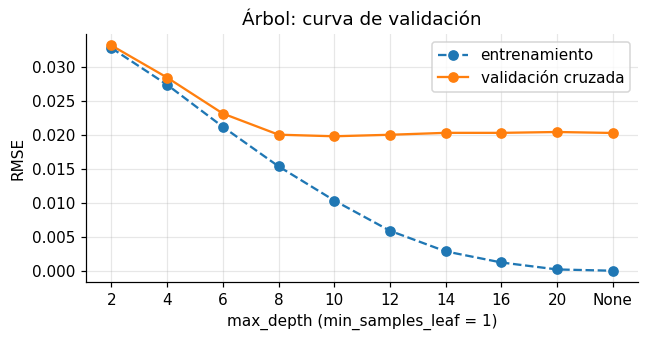

In [17]:
profundidades = [2, 4, 6, 8, 10, 12, 14, 16, 20, None]
filas = []
for d in profundidades:
    r = cross_validate(DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE), X, y, cv=kf,
                       scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
    filas.append({"max_depth": "None" if d is None else d, "RMSE_entren": -r["train_score"].mean(), "RMSE_CV": -r["test_score"].mean()})
curva_arbol = pd.DataFrame(filas)
print(curva_arbol.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(len(curva_arbol)), curva_arbol["RMSE_entren"], "o--", label="entrenamiento")
ax.plot(range(len(curva_arbol)), curva_arbol["RMSE_CV"], "o-", label="validación cruzada")
ax.set_xticks(range(len(curva_arbol))); ax.set_xticklabels(curva_arbol["max_depth"])
ax.set_xlabel("max_depth (min_samples_leaf = 1)"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("Árbol: curva de validación")
plt.tight_layout(); plt.show()

In [18]:
t0 = time.time()
malla_arbol = {"max_depth": [6, 8, 10, 12, 15, None], "min_samples_leaf": [1, 5, 10, 20, 40]}
busq_arbol = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE), malla_arbol, cv=kf,
                          scoring=METRICAS, refit="RMSE", return_train_score=True, n_jobs=-1)
busq_arbol.fit(X, y)
print(f"Mejores hiperparámetros: {busq_arbol.best_params_}   RMSE CV = {-busq_arbol.best_score_:.5f}   ({time.time() - t0:.1f} s)")

res_a = pd.DataFrame(busq_arbol.cv_results_)
res_a["max_depth"] = res_a["param_max_depth"].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else int(v))
tabla_arbol = (res_a.assign(RMSE=-res_a["mean_test_RMSE"])
               .pivot(index="max_depth", columns="param_min_samples_leaf", values="RMSE")
               .reindex([6, 8, 10, 12, 15, "None"]))
print("\nRMSE de validación cruzada (filas: max_depth, columnas: min_samples_leaf):")
print(tabla_arbol.round(5).to_string())

Mejores hiperparámetros: {'max_depth': 15, 'min_samples_leaf': 10}   RMSE CV = 0.01836   (0.7 s)

RMSE de validación cruzada (filas: max_depth, columnas: min_samples_leaf):
param_min_samples_leaf       1        5        10       20       40
max_depth                                                          
6                       0.02319  0.02317  0.02318  0.02321  0.02331
8                       0.02007  0.01978  0.01974  0.01972  0.02019
10                      0.01984  0.01891  0.01865  0.01884  0.01983
12                      0.02006  0.01873  0.01837  0.01874  0.01981
15                      0.02031  0.01867  0.01836  0.01874  0.01981
None                    0.02032  0.01867  0.01836  0.01874  0.01981


Árbol (max_depth=15, min_samples_leaf=10)
RMSE = 0.01836 ± 0.00041 | MAE = 0.01422 ± 0.00029 | R² = 0.7526 ± 0.0150 | RMSE entren. = 0.01205
Hojas: 624   profundidad real: 15


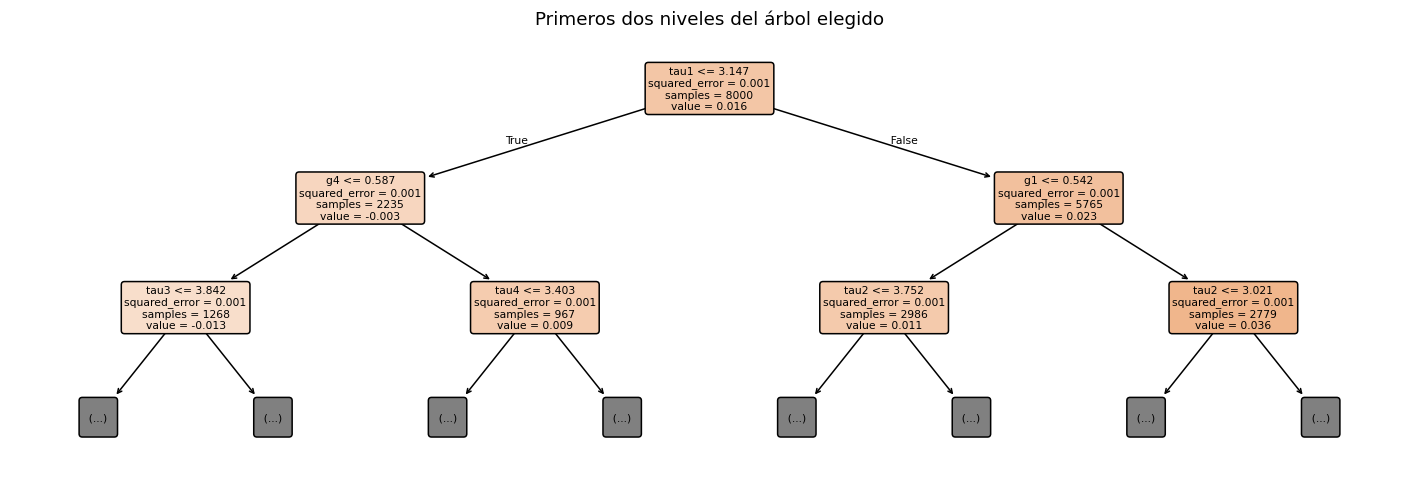

In [19]:
p = busq_arbol.best_params_
nombre_arbol = f"Árbol (max_depth={p['max_depth']}, min_samples_leaf={p['min_samples_leaf']})"
resultados[nombre_arbol] = desde_busqueda(busq_arbol)
finales[nombre_arbol] = busq_arbol.best_estimator_
arbol = busq_arbol.best_estimator_
print(nombre_arbol); print(muestra(resultados[nombre_arbol]))
print(f"Hojas: {arbol.get_n_leaves()}   profundidad real: {arbol.get_depth()}")

fig, ax = plt.subplots(figsize=(13, 4.5))
plot_tree(arbol, max_depth=2, feature_names=PREDICTORES, filled=True, rounded=True, fontsize=7, ax=ax, precision=3)
ax.set_title("Primeros dos niveles del árbol elegido"); plt.tight_layout(); plt.show()

**Interpretacion:**
- **Curva de validación:** el error de entrenamiento baja sin parar hasta 0 (árbol sin límite: memoriza), mientras que el de validación tiene su mínimo alrededor de `max_depth` = 10 (0.01984) y luego sube ligeramente: más profundidad solo agrega varianza.
- **Búsqueda conjunta:** la mejor combinación es **`max_depth` = 15 y `min_samples_leaf` = 10** (RMSE CV 0.01836, $R^2$ = 0.753, 624 hojas). Con profundidad ≥ 12 los resultados casi no cambian: el freno efectivo es `min_samples_leaf`. Exigir al menos 10 datos por hoja promedia el ruido y estabiliza las predicciones; con 1 dato por hoja el error es 0.0203 y con 40 vuelve a subir (0.0198) por falta de flexibilidad.

El árbol supera al modelo lineal, pero queda lejos de los polinomios y del SVR: `stab` depende de forma **suave** de combinaciones de las 11 variables, y un árbol solo puede aproximarla con escalones (rectángulos alineados a los ejes). Necesita cientos de hojas y aun así conserva sesgo, además de su varianza característica.

## 4. Comparación de resultados (validación cruzada de 5 particiones)

In [20]:
tabla = pd.DataFrame(resultados).T
tabla.insert(0, "familia", ["Lineal", "Polinomial", "Polinomial + Ridge", "SVR", "Árbol"])
for c in ["RMSE", "RMSE_std", "MAE", "MAE_std", "R2", "R2_std", "RMSE_entren"]:
    tabla[c] = tabla[c].astype(float)
tabla["brecha_%"] = 100 * (tabla["RMSE"] / tabla["RMSE_entren"] - 1)
tabla["mejora_vs_base_%"] = 100 * (1 - tabla["RMSE"] / base["RMSE"])
tabla = tabla.sort_values("RMSE")

cols = ["familia", "RMSE", "RMSE_std", "MAE", "MAE_std", "R2", "R2_std", "RMSE_entren", "brecha_%", "mejora_vs_base_%"]
tabla_comparativa = tabla[cols].copy()
print(f"Línea base (predecir la media): RMSE = {base['RMSE']:.5f}\n")
# Redondeo sin depender de jinja2 (pandas .style lo requiere)
decimales = {"RMSE": 5, "RMSE_std": 5, "MAE": 5, "MAE_std": 5, "R2": 4, "R2_std": 4,
             "RMSE_entren": 5, "brecha_%": 1, "mejora_vs_base_%": 1}
tabla_comparativa.round(decimales)

Línea base (predecir la media): RMSE = 0.03694



,familia,RMSE,RMSE_std,MAE,MAE_std,R2,R2_std,RMSE_entren,brecha_%,mejora_vs_base_%
"SVR RBF (C=0.1, γ=0.1, ε=0.001)",SVR,0.00734,0.00016,0.00470,0.00007,0.9605,0.0018,0.00473,55.3,80.1
Polinomial grado 4 + Ridge (α=1),Polinomial + Ridge,0.00812,0.00015,0.00563,0.00015,0.9517,0.0008,0.00590,37.7,78.0
Polinomial grado 4 (sin reg.),Polinomial,0.00812,0.00015,0.00564,0.00015,0.9517,0.0008,0.00590,37.7,78.0
"Árbol (max_depth=15, min_samples_leaf=10)",Árbol,0.01836,0.00041,0.01422,0.00029,0.7526,0.0150,0.01205,52.4,50.3
Regresión lineal,Lineal,0.02209,0.00047,0.01754,0.00045,0.6422,0.0176,0.02205,0.2,40.2


RMSE de validación en cada una de las 5 particiones:
                                            fold 1   fold 2   fold 3   fold 4   fold 5
SVR RBF (C=0.1, γ=0.1, ε=0.001)            0.00734  0.00723  0.00741  0.00714  0.00760
Polinomial grado 4 + Ridge (α=1)           0.00822  0.00812  0.00833  0.00798  0.00795
Polinomial grado 4 (sin reg.)              0.00823  0.00812  0.00833  0.00798  0.00795
Árbol (max_depth=15, min_samples_leaf=10)  0.01812  0.01801  0.01832  0.01916  0.01819
Regresión lineal                           0.02238  0.02143  0.02184  0.02198  0.02282


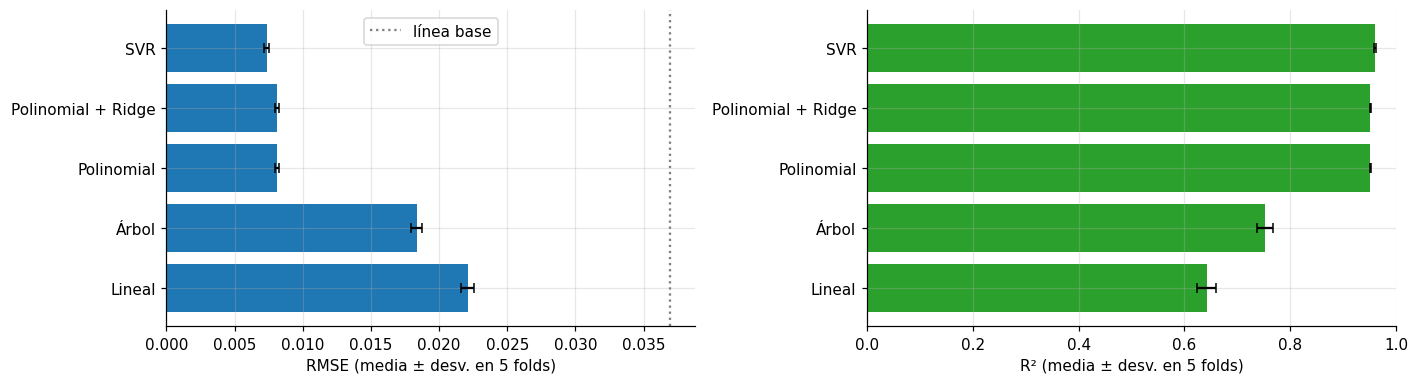

In [21]:
print("RMSE de validación en cada una de las 5 particiones:")
print(pd.DataFrame({n: resultados[n]["RMSE_por_fold"] for n in tabla.index}, index=[f"fold {i+1}" for i in range(5)]).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
etiquetas = tabla["familia"]
axes[0].barh(etiquetas, tabla["RMSE"], xerr=tabla["RMSE_std"], capsize=3, color="C0")
axes[0].axvline(base["RMSE"], color="gray", ls=":", label="línea base")
axes[0].set_xlabel("RMSE (media ± desv. en 5 folds)"); axes[0].invert_yaxis(); axes[0].legend()
axes[1].barh(etiquetas, tabla["R2"], xerr=tabla["R2_std"], capsize=3, color="C2")
axes[1].set_xlabel("R² (media ± desv. en 5 folds)"); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

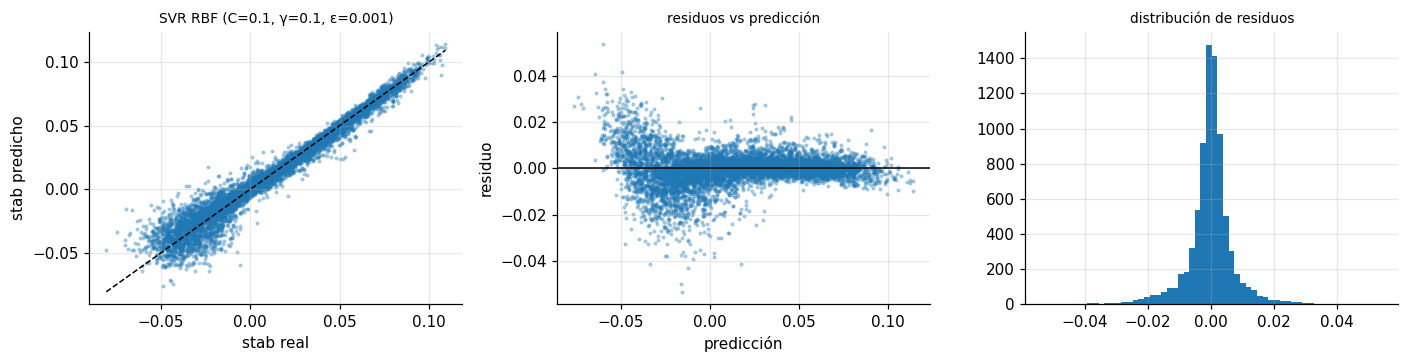

Mejor modelo: SVR RBF (C=0.1, γ=0.1, ε=0.001)
Residuo medio: -0.000180   |   el signo de stab (estable/inestable) coincide en 97.2 % de los casos


In [22]:
# Residuos del mejor modelo (predicciones fuera de partición de la validación cruzada)
mejor = tabla.index[0]
pred_cv = cross_val_predict(finales[mejor], X, y, cv=kf, n_jobs=-1)
residuo = y - pred_cv
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].scatter(y, pred_cv, s=3, alpha=0.3); lim = [y.min(), y.max()]; axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlabel("stab real"); axes[0].set_ylabel("stab predicho"); axes[0].set_title(mejor, fontsize=9)
axes[1].scatter(pred_cv, residuo, s=3, alpha=0.3); axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("predicción"); axes[1].set_ylabel("residuo"); axes[1].set_title("residuos vs predicción", fontsize=9)
axes[2].hist(residuo, bins=60); axes[2].set_title("distribución de residuos", fontsize=9)
plt.tight_layout(); plt.show()
signo_ok = np.mean(np.sign(pred_cv) == np.sign(y))
print(f"Mejor modelo: {mejor}")
print(f"Residuo medio: {residuo.mean():.6f}   |   el signo de stab (estable/inestable) coincide en {100 * signo_ok:.1f} % de los casos")

#### **A)** ¿Qué modelo tuvo mejor desempeño?

| Lugar | Modelo | RMSE CV (media ± desv.) | $R^2$ CV | Diagnóstico |
|---|---|---|---|---|
| 1 | **SVR RBF** (C = 0.1, γ = 0.1, ε = 0.001) | **0.00734 ± 0.00016** | **0.961** | bajo sesgo; brecha moderada |
| 2 | Polinomial grado 4 + Ridge (α = 1) | 0.00812 ± 0.00015 | 0.952 | bajo sesgo; brecha 38 % |
| 2 | Polinomial grado 4 (sin regularización) | 0.00812 ± 0.00015 | 0.952 | igual que con Ridge |
| 4 | Árbol (max_depth = 15, min_samples_leaf = 10) | 0.01836 ± 0.00041 | 0.753 | escalones: sesgo y varianza |
| 5 | Regresión lineal | 0.02209 ± 0.00047 | 0.642 | sesgo alto (subajuste) |



Claramente, se puede observar que el mejor es el **SVR con kernel RBF**. Comparado con la línea base, que siempre predice el promedio, reduce el RMSE en un 80 %, y supera al polinomial de grado 4, su competidor más cercano, en un 9.6 %. Esa diferencia (0.00078) es unas cinco veces mayor que lo que varía el error de una partición a otra, y además el SVR gana en **las cinco particiones**. Su ventaja es consistente y no producto del azar. Sus residuos están centrados en cero (media de −0.0002), y si solo nos fijamos en el signo de `stab`, acierta si el sistema es estable o inestable en el **97 %** de los casos.

Desde la perspectiva de sesgo y varianza, cada modelo falla por razones distintas. La regresión lineal tiene **sesgo alto**: sus errores de entrenamiento y de validación son casi iguales y ambos altos, señal de que el modelo es demasiado simple para la relación. El polinomio de grado 4 y el SVR tienen **sesgo bajo**; muestran cierta brecha entre entrenamiento y validación, es decir, algo de varianza, que se mantiene bajo control gracias al grado elegido y a los valores de C y γ. El árbol queda en medio: arrastra el sesgo de aproximar una relación suave con escalones y, además, la varianza que caracteriza a los árboles.

La regularización no hizo diferencia: Ridge y el polinomio sin regularizar empatan. Con 8,000 filas hay datos de sobra para estimar los coeficientes, y Ridge aporta sobre todo cuando el número de variables se acerca al de observaciones.

Conviene tomar estas cifras con una precaución: el RMSE de validación de cada familia corresponde a la mejor combinación de su malla, así que es ligeramente optimista, porque se eligió precisamente por ser la mejor. Una validación cruzada anidada daría una estimación más honesta, pero las diferencias entre familias son mucho mayores que ese sesgo y no cambiarían el orden.

Por último, el desempeño no lo es todo. El SVR es el modelo más costoso (es la búsqueda más lenta del notebook y el modelo final guarda unos 6,100 vectores de soporte) y también el menos interpretable. El polinomial de grado 4 queda muy cerca en error, es mucho más rápido de entrenar y de usar, y sus coeficientes son explícitos. Si el costo de cómputo importa, es la mejor alternativa.

## 5. Evaluación final en el conjunto de prueba

Cada modelo de la tabla ya está **reentrenado con las 8,000 filas** de entrenamiento con su mejor configuración (la de la validación cruzada). La celda siguiente:

1. Lee `electrical_grid_stability_test.csv` (2,000 filas) desde la misma carpeta del notebook.
2. Usa los mismos 11 predictores y genera las predicciones de `stab` de los cinco modelos. Se guardaran en `predicciones_test.csv`.
3. Si el archivo de prueba contiene la columna `stab` (o si se cargan las etiquetas en `Y_TEST`), calcula e imprime el **RMSE de cada modelo**. Si no hay etiquetas, lo indica sin interrumpir la ejecución.

In [23]:
RUTA_TEST = Path("electrical_grid_stability_test.csv")
RUTA_PREDICCIONES = Path("predicciones_test.csv")
Y_TEST = None    # Si el CSV de prueba no trae 'stab', cargar aquí las etiquetas reales (mismo orden de filas). Ej.: pd.read_csv("stab_test.csv")["stab"]

if not RUTA_TEST.exists():
    print(f"No se encontró '{RUTA_TEST}'. Validar que el archivo esté en la carpeta del notebook y volver a ejecutar esta celda.")
else:
    test = pd.read_csv(RUTA_TEST)
    print("Conjunto de prueba:", test.shape)
    faltan = [c for c in PREDICTORES if c not in test.columns]
    assert not faltan, f"Faltan columnas en el archivo de prueba: {faltan}"
    X_test = test[PREDICTORES]

    predicciones = pd.DataFrame({nombre: modelo.predict(X_test) for nombre, modelo in finales.items()}, index=test.index)
    predicciones.to_csv(RUTA_PREDICCIONES, index_label="fila")
    print(f"Predicciones guardadas en '{RUTA_PREDICCIONES}' ({predicciones.shape[0]} filas × {predicciones.shape[1]} modelos)")
    display(predicciones.head())

    y_test = test[OBJETIVO] if OBJETIVO in test.columns else Y_TEST
    if y_test is None:
        print("\nEl archivo de prueba no incluye la columna 'stab': el RMSE de prueba se calculará cuando se disponga de las etiquetas.")
    else:
        y_test = np.asarray(y_test)
        rmse_test = pd.DataFrame({
            "RMSE_prueba": {n: mean_squared_error(y_test, predicciones[n]) ** 0.5 for n in predicciones},
            "MAE_prueba": {n: mean_absolute_error(y_test, predicciones[n]) for n in predicciones},
            "R2_prueba": {n: r2_score(y_test, predicciones[n]) for n in predicciones},
            "RMSE_CV": {n: resultados[n]["RMSE"] for n in predicciones}}).sort_values("RMSE_prueba")
        print("\nRMSE de cada modelo en el conjunto de prueba:")
        for n, v in rmse_test["RMSE_prueba"].items():
            print(f"  {n:<55s} RMSE = {v:.5f}")
        display(rmse_test.round(5))

No se encontró 'electrical_grid_stability_test.csv'. Validar que el archivo esté en la carpeta del notebook y volver a ejecutar esta celda.


## 6. Conclusiones

1. **Modelo recomendado: SVR con kernel RBF** (C = 0.1, γ = 0.1, ε = 0.001, con `StandardScaler` en el `Pipeline`). Obtuvo el menor error en la validación cruzada de 5 folds: RMSE = 0.00734 ± 0.00016, $R^2$ = 0.961, frente a 0.0369 de la línea base. Ganó en todas las particiones.
2. **Alternativa eficiente: polinomial de grado 4** (con o sin Ridge): RMSE = 0.00812, $R^2$ = 0.952, más rápido y con coeficientes explícitos.
3. **La regularización no cambió el resultado** porque hay muchos datos por coeficiente; su valor aparece cuando el número de variables se acerca al de observaciones.
4. **La relación es no lineal.** La regresión lineal subajusta ($R^2$ = 0.64) y el árbol, aun bien podado, la aproxima con escalones ($R^2$ = 0.75). Los modelos que captan interacciones suaves (polinomios y kernels) son claramente superiores.
5. **Conjunto de prueba:** los cinco modelos quedan reentrenados con las 8,000 filas y la sección 5 genera `predicciones_test.csv` con sus predicciones para las 2,000 filas de `electrical_grid_stability_test.csv`. Cuando se disponga de la columna `stab`, la misma celda calcula e imprime el RMSE de cada modelo. Por la validación cruzada se espera para el SVR un RMSE de prueba del orden de 0.0073.
6. **Limitaciones y siguientes pasos:**
   - Los datos son simulados.
   - El error de validación del mejor candidato de cada malla es ligeramente optimista; la validación cruzada anidada daría una estimación más honesta.
   - El SVR es costoso.
   - Como mejoras, se podría refinar la malla del SVR (γ entre 0.05 y 0.1, ε < 0.001), crear variables de interacción como `tau × g`, o probar ensambles (bosques aleatorios, boosting) en el Módulo 4.